# Phase 5: Federated Predictive Maintenance (Flower / FedAvg)
### Collaborative Training across Simulated Factory Clients without Raw Data Sharing

In this notebook, we evaluate Federated Learning for industrial predictive maintenance using **Flower (`flwr`)**. We simulate $K=3$ independent factories holding private turbofan fleets and analyze the accuracy trade-offs of:
1. **Centralized CNN-LSTM**: Upper bound (pooled raw sensor data)
2. **Local-Only Models**: Lower bound (each factory trains in isolation without collaboration)
3. **Federated IID (FedAvg)**: Homogeneous fleet partitions
4. **Federated Non-IID (FedAvg)**: Heterogeneous operational lifespans across factories

In [1]:
import sys
sys.path.append('..')
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import Image

from src.utils.config import TABLES_DIR, FIGURES_DIR

sns.set_theme(style='whitegrid')
%matplotlib inline

## 1. Master Federated Comparison Results Table
Loads empirical results scored against the held-out NASA C-MAPSS FD001 test set.

In [2]:
fed_path = TABLES_DIR / 'federated_comparison.csv'
df_fed = pd.read_csv(fed_path)
df_fed

,Setup,MAE,RMSE,R2,NASA_Score
0,Centralized CNN-LSTM (Upper Bound),10.087404,15.014803,0.859612,642.047540
1,Local-Only Average (IID Shards),12.494378,17.470520,0.809167,739.326169
2,Local-Only Average (Non-IID Shards),13.629593,19.219580,0.768884,1365.085951
3,Federated IID (FedAvg),11.417859,15.185687,0.856398,371.467893
4,Federated Non-IID (FedAvg),9.312020,13.415630,0.887924,315.518913


## 2. Federated vs. Centralized vs. Local-Only Trade-Off Analysis

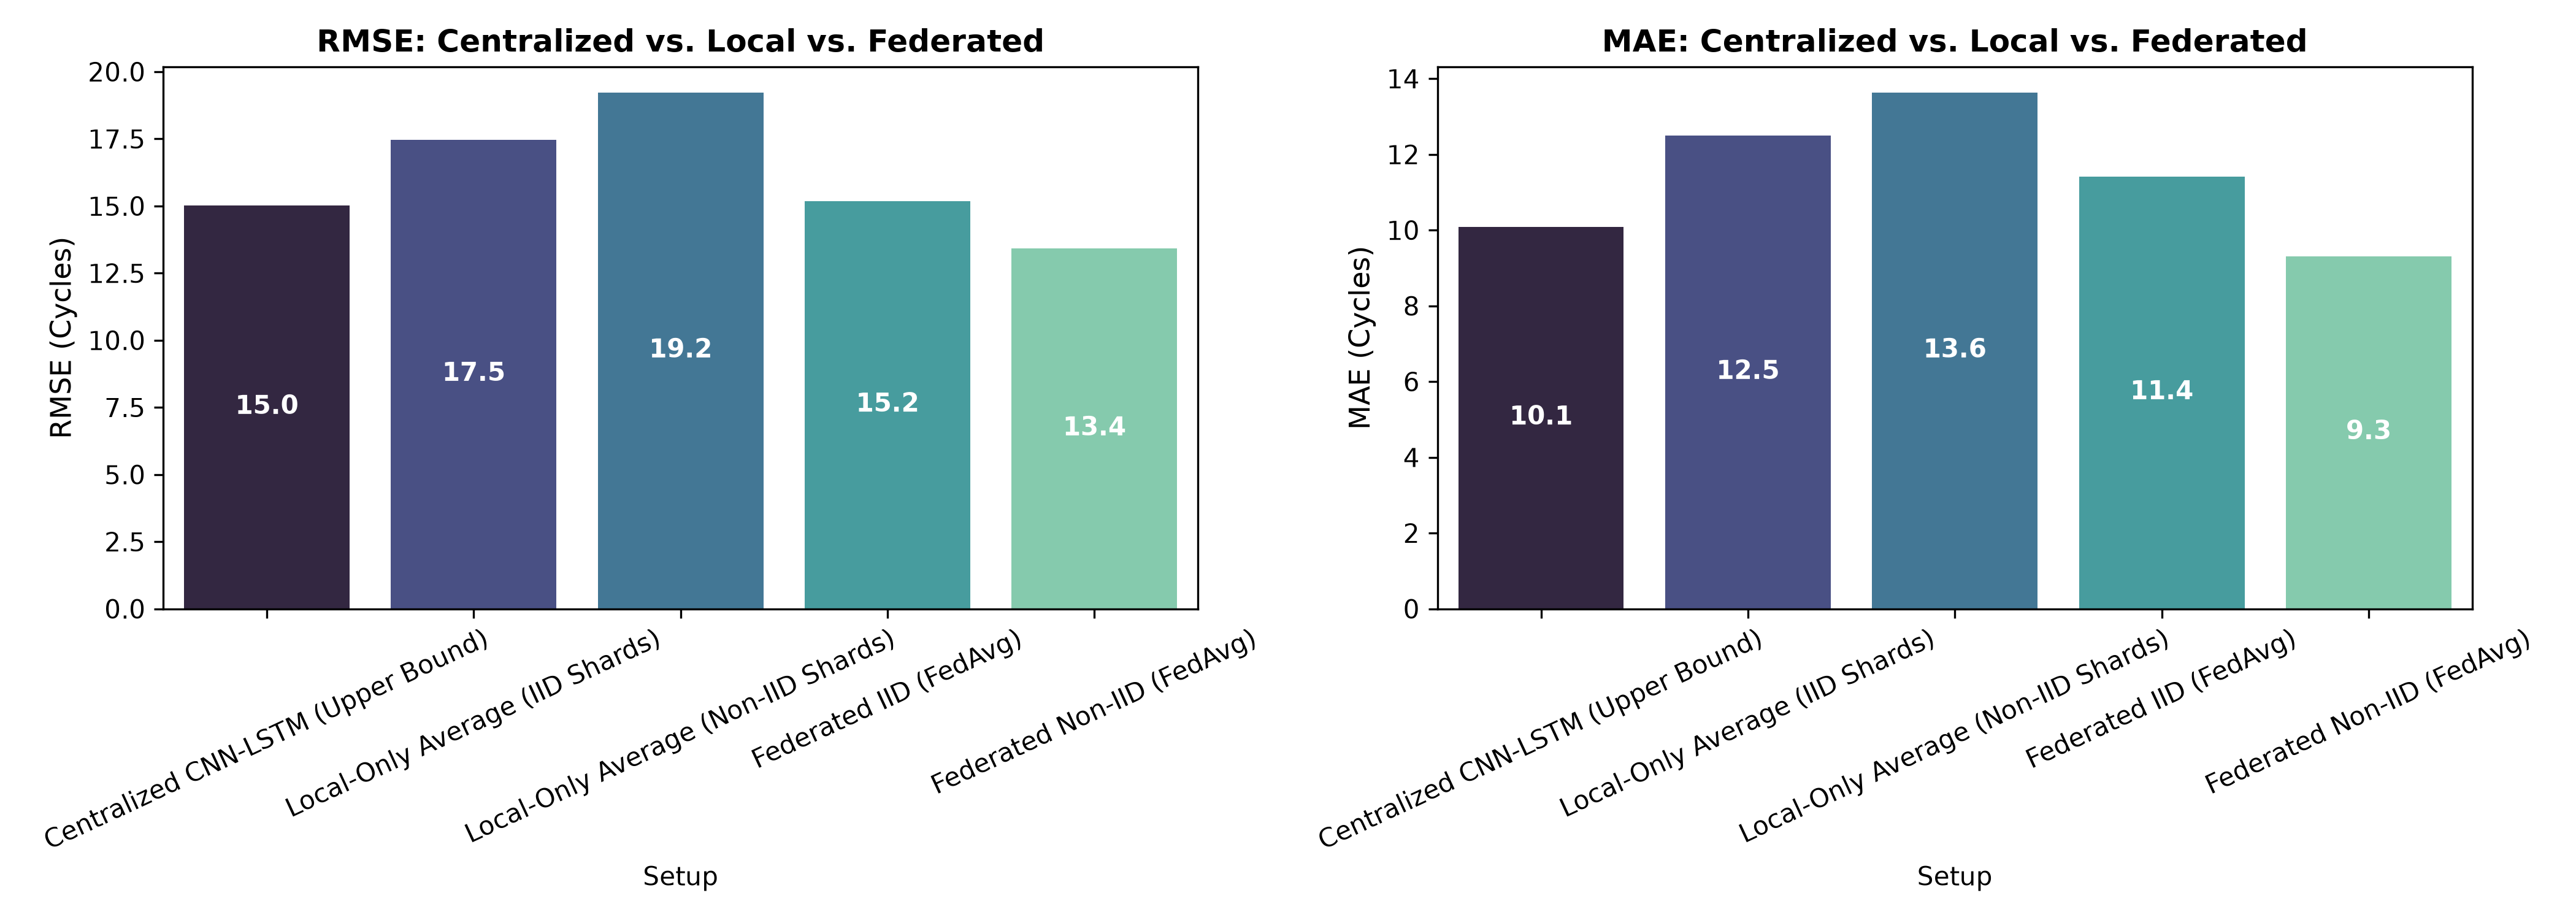

In [3]:
Image(filename=str(FIGURES_DIR / 'federated_vs_centralized_tradeoff.png'))

## 3. Communication Convergence Curves (FedAvg IID vs. Non-IID)
Shows global model test MAE and RMSE across communication rounds.

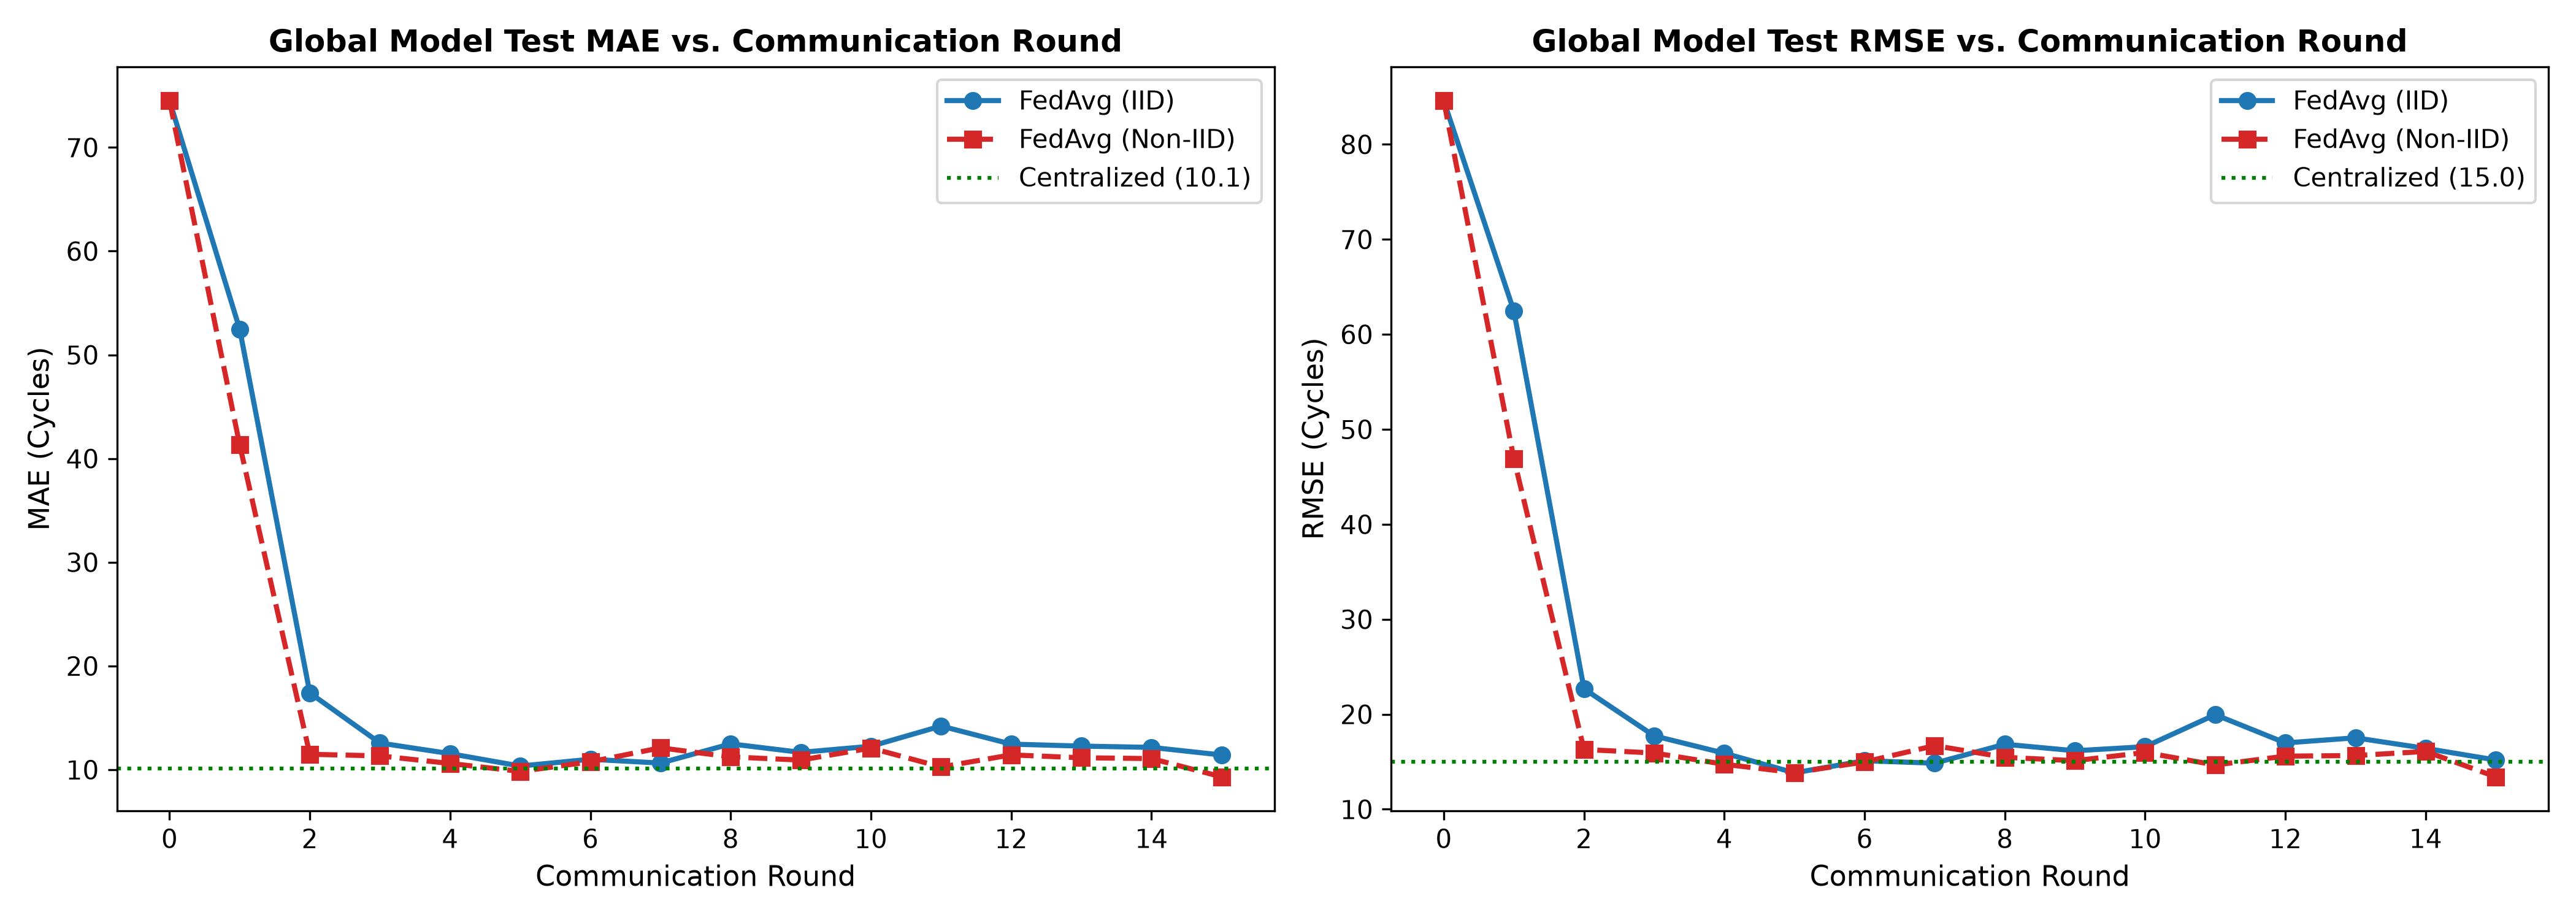

In [4]:
Image(filename=str(FIGURES_DIR / 'fl_convergence_curves.png'))

## 4. In-Depth Technical Insights & Discussion

### 1. The Value of Collaboration (Federated vs. Local-Only)
- When factories train isolated models on their own private data, performance degrades sharply: **Local-Only Average RMSE is 19.22 cycles (Non-IID)** and 17.47 (IID).
- Collaborative FedAvg training achieves **RMSE 13.42 cycles (Non-IID)**, representing a **30.2% reduction in error** over isolated training, without any factory sharing raw sensor readings.

### 2. The Non-IID Phenomenon
- When engines are partitioned heterogeneously by lifespan (short-lived vs. long-lived), isolated local clients suffer catastrophic blindspots: Client 1 (medium lifespans) has an RMSE of 20.79 cycles and an asymmetric NASA penalty of >1300.
- Federated aggregation over rounds shares complementary degradation parameters across fleets, enabling the global model to generalize across all operating stress regimes.

### 3. Privacy & Industrial Compliance
- Industrial sensor time-series contain proprietary operational profiles, duty cycles, and flight schedules.
- Under Flower's FedAvg architecture, clients exchange only 1D-Conv and LSTM weight matrices $\Delta W$, maintaining local data sovereignty.